In [1]:
%pip install nltk scikit-learn textblob wordcloud matplotlib tensorflow

Clean text:
 artificial intelligence is changing the world
ai helps people solve difficult problems
machine learning allows computers to learn from data
python is a popular language for building ai applications
i enjoy learning about ai because it is useful and exciting


Words: ['artificial', 'intelligence', 'is', 'changing', 'the', 'world', 'ai', 'helps', 'people', 'solve', 'difficult', 'problems', 'machine', 'learning', 'allows', 'computers', 'to', 'learn', 'from', 'data', 'python', 'is', 'a', 'popular', 'language', 'for', 'building', 'ai', 'applications', 'i', 'enjoy', 'learning', 'about', 'ai', 'because', 'it', 'is', 'useful', 'and', 'exciting']

Sentences: ['Artificial intelligence is changing the world.', 'AI helps people solve difficult problems.', 'Machine learning allows computers to learn from data.', 'Python is a popular language for building AI applications.', 'I enjoy learning about AI because it is useful and exciting.']

Using split(): ['artificial', 'intelligence', 'is

<Axes: title={'center': 'Word Frequency Distribution'}, xlabel='Samples', ylabel='Counts'>

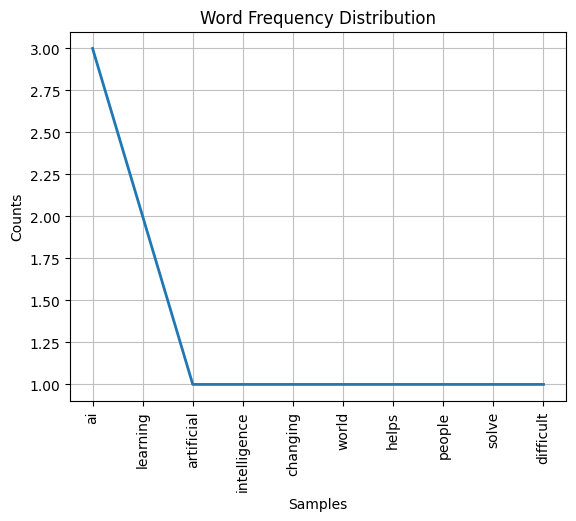

In [5]:
import re
import nltk
from nltk.tokenize import word_tokenize, sent_tokenize
from nltk.corpus import stopwords
from nltk.probability import FreqDist
text = """Artificial intelligence is changing the world.
AI helps people solve difficult problems.
Machine learning allows computers to learn from data.
Python is a popular language for building AI applications.
I enjoy learning about AI because it is useful and exciting.
"""
clean_text = re.sub(r'[^\w\s]', '', text.lower())
print("Clean text:\n", clean_text)
words = word_tokenize(clean_text)
sentences = sent_tokenize(text)
print("\nWords:", words)
print("\nSentences:", sentences)
print("\nUsing split():", clean_text.split())
print("\nUsing word_tokenize():", word_tokenize(clean_text))
stop_words = set(stopwords.words('english'))
filtered_words = [
    word for word in words
    if word.isalpha() and word not in stop_words
]
print("\nWords after removing stopwords:", filtered_words)
frequency = FreqDist(filtered_words)
print("\nWord frequencies:", frequency.most_common())
frequency.plot(10, title="Word Frequency Distribution")

In [6]:
import re
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer, WordNetLemmatizer
from nltk.tokenize import word_tokenize
words = re.findall(r'\b[a-zA-Z]+\b', text.lower())
stop_words = set(stopwords.words('english'))
filtered_words = [
    word for word in words
    if word not in stop_words
]
stemmer = PorterStemmer()
stemmed_words = [
    stemmer.stem(word) for word in filtered_words
]
lemmatizer = WordNetLemmatizer()
lemmatized_words = [
    lemmatizer.lemmatize(word) for word in filtered_words
]
print("Original words:", filtered_words)
print("Stemmed words:", stemmed_words)
print("Lemmatized words:", lemmatized_words)

Original words: ['artificial', 'intelligence', 'changing', 'world', 'ai', 'helps', 'people', 'solve', 'difficult', 'problems', 'machine', 'learning', 'allows', 'computers', 'learn', 'data', 'python', 'popular', 'language', 'building', 'ai', 'applications', 'enjoy', 'learning', 'ai', 'useful', 'exciting']
Stemmed words: ['artifici', 'intellig', 'chang', 'world', 'ai', 'help', 'peopl', 'solv', 'difficult', 'problem', 'machin', 'learn', 'allow', 'comput', 'learn', 'data', 'python', 'popular', 'languag', 'build', 'ai', 'applic', 'enjoy', 'learn', 'ai', 'use', 'excit']
Lemmatized words: ['artificial', 'intelligence', 'changing', 'world', 'ai', 'help', 'people', 'solve', 'difficult', 'problem', 'machine', 'learning', 'allows', 'computer', 'learn', 'data', 'python', 'popular', 'language', 'building', 'ai', 'application', 'enjoy', 'learning', 'ai', 'useful', 'exciting']


In [7]:
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer

# Three short texts of your own
texts = [
    "Artificial intelligence helps doctors detect diseases.",
    "Machine learning improves artificial intelligence systems.",
    "Doctors use technology to improve healthcare."
]
count_vectorizer = CountVectorizer()
bow_matrix = count_vectorizer.fit_transform(texts)
print("Bag of Words:")
print("Features:", count_vectorizer.get_feature_names_out())
print(bow_matrix.toarray())
tfidf_vectorizer = TfidfVectorizer()
tfidf_matrix = tfidf_vectorizer.fit_transform(texts)
print("\nTF-IDF:")
print("Features:", tfidf_vectorizer.get_feature_names_out())
print(tfidf_matrix.toarray().round(3))
feature_names = tfidf_vectorizer.get_feature_names_out()
for i, row in enumerate(tfidf_matrix.toarray()):
    top_indices = row.argsort()[::-1][:3]
    keywords = [
        (feature_names[j], round(row[j], 3))
        for j in top_indices
    ]
    print(f"\nText {i+1} top keywords:", keywords)

Bag of Words:
Features: ['artificial' 'detect' 'diseases' 'doctors' 'healthcare' 'helps' 'improve'
 'improves' 'intelligence' 'learning' 'machine' 'systems' 'technology'
 'to' 'use']
[[1 1 1 1 0 1 0 0 1 0 0 0 0 0 0]
 [1 0 0 0 0 0 0 1 1 1 1 1 0 0 0]
 [0 0 0 1 1 0 1 0 0 0 0 0 1 1 1]]

TF-IDF:
Features: ['artificial' 'detect' 'diseases' 'doctors' 'healthcare' 'helps' 'improve'
 'improves' 'intelligence' 'learning' 'machine' 'systems' 'technology'
 'to' 'use']
[[0.349 0.46  0.46  0.349 0.    0.46  0.    0.    0.349 0.    0.    0.
  0.    0.    0.   ]
 [0.335 0.    0.    0.    0.    0.    0.    0.44  0.335 0.44  0.44  0.44
  0.    0.    0.   ]
 [0.    0.    0.    0.322 0.423 0.    0.423 0.    0.    0.    0.    0.
  0.423 0.423 0.423]]

Text 1 top keywords: [('detect', np.float64(0.46)), ('diseases', np.float64(0.46)), ('helps', np.float64(0.46))]

Text 2 top keywords: [('learning', np.float64(0.44)), ('machine', np.float64(0.44)), ('systems', np.float64(0.44))]

Text 3 top keywords: [('use'

In [8]:
import re
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
ai_text = """
Artificial intelligence helps computers learn from data.
AI systems recognize patterns and solve complex problems.
Machine learning is an important part of artificial intelligence.
AI is used in healthcare, education, and business.
"""
blockchain_text = """
Blockchain stores information in connected digital blocks.
The technology supports secure and transparent transactions.
Blockchain is used in finance and digital currencies.
It can help businesses maintain trustworthy records.
"""
def preprocess(text):
    text = re.sub(r'[^a-zA-Z\s]', '', text.lower())
    return text.split()
words_ai = preprocess(ai_text)
words_blockchain = preprocess(blockchain_text)
print("AI tokens:", words_ai)
print("\nBlockchain tokens:", words_blockchain)
set_ai = set(words_ai)
set_blockchain = set(words_blockchain)
jaccard = len(set_ai & set_blockchain) / len(set_ai | set_blockchain)
print("\nJaccard similarity:", round(jaccard, 3))
vectorizer = TfidfVectorizer()
tfidf = vectorizer.fit_transform([ai_text, blockchain_text])
cosine = cosine_similarity(tfidf[0:1], tfidf[1:2])[0][0]
print("Cosine similarity:", round(cosine, 3))

AI tokens: ['artificial', 'intelligence', 'helps', 'computers', 'learn', 'from', 'data', 'ai', 'systems', 'recognize', 'patterns', 'and', 'solve', 'complex', 'problems', 'machine', 'learning', 'is', 'an', 'important', 'part', 'of', 'artificial', 'intelligence', 'ai', 'is', 'used', 'in', 'healthcare', 'education', 'and', 'business']

Blockchain tokens: ['blockchain', 'stores', 'information', 'in', 'connected', 'digital', 'blocks', 'the', 'technology', 'supports', 'secure', 'and', 'transparent', 'transactions', 'blockchain', 'is', 'used', 'in', 'finance', 'and', 'digital', 'currencies', 'it', 'can', 'help', 'businesses', 'maintain', 'trustworthy', 'records']

Jaccard similarity: 0.083
Cosine similarity: 0.132



Review: The phone is excellent and the battery lasts long.
Polarity: 0.475
Subjectivity: 0.7
Sentiment: Positive

Review: I love this phone because it is fast and reliable.
Polarity: 0.35
Subjectivity: 0.6
Sentiment: Positive

Review: The camera is terrible and the battery is weak.
Polarity: -0.688
Subjectivity: 0.812
Sentiment: Negative

Review: The product is disappointing and very slow.
Polarity: -0.495
Subjectivity: 0.61
Sentiment: Negative

Review: The phone has a screen and a charging port.
Polarity: 0.0
Subjectivity: 0.0
Sentiment: Neutral


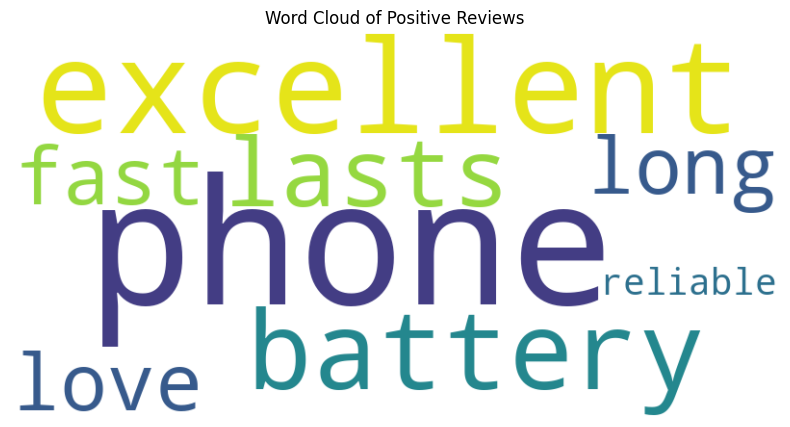

In [9]:
from textblob import TextBlob
from wordcloud import WordCloud
import matplotlib.pyplot as plt
reviews = [
    "The phone is excellent and the battery lasts long.",
    "I love this phone because it is fast and reliable.",
    "The camera is terrible and the battery is weak.",
    "The product is disappointing and very slow.",
    "The phone has a screen and a charging port."
]
positive_reviews = []
for review in reviews:
    analysis = TextBlob(review).sentiment
    polarity = analysis.polarity
    subjectivity = analysis.subjectivity

    if polarity > 0:
        sentiment = "Positive"
        positive_reviews.append(review)
    elif polarity < 0:
        sentiment = "Negative"
    else:
        sentiment = "Neutral"

    print("\nReview:", review)
    print("Polarity:", round(polarity, 3))
    print("Subjectivity:", round(subjectivity, 3))
    print("Sentiment:", sentiment)
if positive_reviews:
    positive_text = " ".join(positive_reviews)

    wordcloud = WordCloud(
        width=800,
        height=400,
        background_color="white"
    ).generate(positive_text)

    plt.figure(figsize=(10, 5))
    plt.imshow(wordcloud, interpolation="bilinear")
    plt.axis("off")
    plt.title("Word Cloud of Positive Reviews")
    plt.show()
else:
    print("No positive reviews available.")

In [10]:
import numpy as np
import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense
training_text = """
Python is a popular programming language.
Python helps students learn computer programming.
Students use Python to solve problems and build projects.
Programming develops logical thinking and creativity.
Machine learning uses data to make useful predictions.
Artificial intelligence helps computers perform intelligent tasks.
Students can use Python to explore artificial intelligence.
Learning programming requires practice and patience.
Small projects help students understand difficult concepts.
Technology continues to change the way people learn and work.
Python provides many libraries for data science.
These libraries help people analyze information and build models.
Learning new skills can create opportunities for the future.
"""
tokenizer = Tokenizer()
tokenizer.fit_on_texts([training_text])
total_words = len(tokenizer.word_index) + 1
sequences = []
for line in training_text.lower().split("."):
    line = line.strip()

    if line:
        token_list = tokenizer.texts_to_sequences([line])[0]

        for i in range(1, len(token_list)):
            sequences.append(token_list[:i + 1])
max_len = max(len(seq) for seq in sequences)
sequences = pad_sequences(
    sequences, maxlen=max_len, padding="pre"
)
X = sequences[:, :-1]
y = sequences[:, -1]
print("Vocabulary size:", total_words)
print("Number of training sequences:", len(X))
model = Sequential([
    Embedding(total_words, 32, input_length=max_len - 1),
    LSTM(64),
    Dense(total_words, activation="softmax")
])
model.compile(
    loss="sparse_categorical_crossentropy",
    optimizer="adam",
    metrics=["accuracy"]
)
model.fit(X, y, epochs=100, verbose=0)
print("Model training completed!")
def generate_text(seed_word, next_words=15):
    result = seed_word.lower()

    for _ in range(next_words):
        token_list = tokenizer.texts_to_sequences([result])[0]
        token_list = pad_sequences(
            [token_list],
            maxlen=max_len - 1,
            padding="pre",
            truncating="pre"
        )

        probabilities = model.predict(token_list, verbose=0)[0]
        predicted_id = int(np.argmax(probabilities))

        if predicted_id == 0:
            break

        output_word = tokenizer.index_word.get(predicted_id)

        if output_word is None:
            break

        result += " " + output_word

    return result

print("\nGenerated text:")
print(generate_text("python", 15))
print(generate_text("students", 15))

Vocabulary size: 66
Number of training sequences: 85


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Model training completed!

Generated text:
python helps helps computers perform intelligent tasks tasks tasks tasks tasks work work work work models
students use python to to problems and build projects models work models models projects projects difficult
